# Assignment 2 – Zero-Shot Image Classification with Transformers

In this assignment, you will apply a pre-trained vision–language transformer (e.g. CLIP) to perform **zero-shot** classification on the Fashion-MNIST dataset—classifying each image without any task-specific training. You will build on the concepts from Assignment 1 by comparing this “off-the-shelf” approach to the CNN you previously trained.

You will:
1. **Load** the Fashion-MNIST images using PyTorch instead of Keras.
2. **Run a zero-shot baseline** with simple text prompts to set a performance reference.
3. **Engineer improved prompts** and measure the resulting accuracy gains.
4. **Visualise image embeddings** with UMAP to inspect class separability.
5. **Conduct one mini-experiment** of your choice.
6. **Summarise findings** and reflect on strengths and weaknesses of zero-shot transformers versus a trained CNN.

# 1. Loading the Fashion-MNIST Dataset

As in assignment 1, we'll load the Fashion-MNIST dataset, but this time using `torchvision.datasets` to ensure compatibility with the `transformers` library. We will also load our model and processor from the `transformers` library.

The transformers library allows us to use pre-trained models like CLIP, which can perform zero-shot classification by leveraging the text prompts we provide. There are two key objects we will use: the `CLIPModel` for the model itself and the `CLIPProcessor` for preparing our images and text prompts.

Since we are not actually training a model in this assignment, we will set the CLIP model to evaluation mode. If the model is designed to utilize features like dropout or batch normalization, setting it to evaluation mode ensures that these features behave correctly during inference (prediction). Setting the model to evaluaton mode also tells PyTorch that we don't have to compute gradients, which can save memory and speed up inference.

In order to speed up processing, we will also move the model to an "accelerator" if available. This is typically a GPU, but modern MacBooks also have an "Apple Silicon" accelerator that can be used for inference, called MPS (Metal Performance Shaders). If you are using a MacBook with Apple Silicon, you can use the MPS device for faster processing.

In [1]:
# Uncomment and run if required
#!pip install transformers torchvision torch accelerate

In [2]:
from transformers import CLIPModel, CLIPProcessor
import torch

clip_model_name = "openai/clip-vit-base-patch32"
clip_model     = CLIPModel.from_pretrained(clip_model_name)
clip_processor = CLIPProcessor.from_pretrained(clip_model_name, use_fast=False)

# Set model to evaluation mode, as we are not training it
clip_model.eval()

# Check for accelerators
device = "cpu" # Default to CPU
if torch.cuda.is_available():
    device = "cuda" # Use GPU if available
elif torch.backends.mps.is_available():
    device = "mps"

clip_model.to(device)

print(f"Using device: {device}")

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

[transformers] The `use_fast` parameter is deprecated and will be removed in a future version. Use `backend="torchvision"` instead of `use_fast=True`, or `backend="pil"` instead of `use_fast=False`.


Using device: cpu


Now we are ready to load the testing set from Fashion-MNIST. We will use the `torchvision.datasets.FashionMNIST` class to load the dataset. We do not need to apply any transformations to the images, as the `CLIPProcessor` ensures any input images are in the format that the model is trained on.

You should:

- [ x ] Use the `torchvision.datasets.FashionMNIST` class to load the *test* split of the dataset. Documentation is available [here](https://pytorch.org/vision/stable/generated/torchvision.datasets.FashionMNIST.html).
- [ x ] Create a PyTorch `DataLoader` to iterate over the dataset in batches. Use a batch size of 16 and set `shuffle=True` to randomise the order of the images. You will also need to supply the provided `collate_clip` function to the `DataLoader collate_fn` argument to ensure the images are processed correctly. Documentation for `DataLoader` is available [here](https://pytorch.org/docs/stable/data.html#torch.utils.data.DataLoader).

In [3]:
from torchvision import datasets
from torch.utils.data import DataLoader

CLASS_NAMES = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

def collate_clip(batch):
    imgs, labels = zip(*batch) # Unzip the batch into images and labels
    proc = clip_processor(images=list(imgs),
                        return_tensors="pt",
                        padding=True) # Process images with CLIPProcessor
    # Send pixel_values to GPU/CPU now; labels stay on CPU for metrics
    return proc["pixel_values"].to(device), torch.tensor(labels)

# downloading of dataset
# datasets.FashionMNIST(".", download = True)

test_dataset = datasets.FashionMNIST(".", train = False)
test_loader = DataLoader(test_dataset, batch_size = 16, shuffle = True, collate_fn = collate_clip)

In [4]:
# Just checking that `train = False` kwarg actually sets the split to the test split.
test_dataset

Dataset FashionMNIST
    Number of datapoints: 10000
    Root location: .
    Split: Test

If your code is correct, the following cell should show the first batch of images from the Fashion-MNIST dataset:

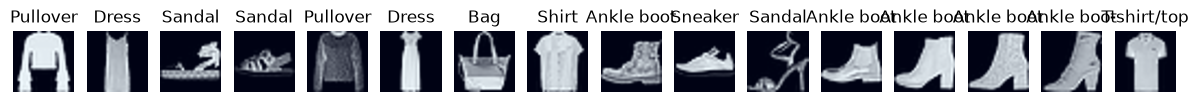

In [5]:
import matplotlib.pyplot as plt

# Display the first batch of images from `test_loader`

def show_batch(loader):
    images, labels = next(iter(loader))
    images = images.cpu()  # Move images to CPU for plotting
    # Renormalize to [0, 1] for visualization
    images = (images - images.min()) / (images.max() - images.min())
    _, axes = plt.subplots(1, len(images), figsize=(15, 5))
    for ax, img, label in zip(axes, images, labels):
        ax.imshow(img.permute(1, 2, 0))
        ax.set_title(CLASS_NAMES[label.item()])
        ax.axis('off')
    plt.show()

show_batch(test_loader)

We’re now ready to run our zero-shot classification baseline!

# Brief Introduction to Zero-Shot Classification

In Assignment 1, we followed the typical machine-learning pipeline: we trained a CNN on the Fashion-MNIST dataset, using labelled examples to update the model’s weights. While effective, that approach requires a curated, task-specific training set—a luxury you don’t always have in practice.

Zero-shot classification flips the script.  A large vision–language model (VLM) such as **CLIP** is first pre-trained on hundreds of millions of image–text pairs scraped from the web.  Because it learns *joint* visual–textual embeddings, the model can later solve new tasks simply by “measuring” how similar an image is to a **text prompt** that describes each candidate class—without seeing a single task-labelled example.

**How it works**  
1. Feed an image through CLIP’s vision encoder → **image feature**.  
2. Feed a textual prompt (e.g. “a photo of a sandal”) through CLIP’s text encoder → **text feature**.  
3. Compute cosine similarity between the image feature and every class’s text feature.  
4. Pick the class whose prompt is most similar.

For our first attempt, we’ll use the bare class names as prompts, e.g.:

- "T-shirt/top"
- "Trouser"

### You should:

- [ x ] Build embeddings: use the `get_text_embeddings` helper function to create text embeddings for the class names.
- [ x ] Run inference: use the `get_image_embeddings` helper function to create image embeddings.
- [ x ] Compute cosine similarity: complete and use the `get_cosine_similarity` helper function to compute the cosine similarity between the image and text embeddings.
- [ x ] Make predictions: use the `get_predictions` helper function to get the predicted class for each image in the batch.

Note that for normalized vectors like the ones we are using, cosine similarity is equivalent to the dot product. This means we can use the handy formula `cosine_similarity = vector_a @ vector_b.T` to compute the similarity between the image and text embeddings.

In [6]:
def get_text_embeddings(class_names: list[str]) -> torch.Tensor:
    """    Get text embeddings for the given class names using CLIP.
    Args:
        class_names (list[str]): List of class names to encode.
    Returns:
        torch.Tensor: Normalized text embeddings for the class names.
    """
    tokenized = clip_processor(text=class_names,
                               padding=True,
                               return_tensors="pt").to(device)
    
    with torch.no_grad():
        text_embeddings = clip_model.get_text_features(**tokenized)

    text_embeddings = text_embeddings.pooler_output
    text_feats = text_embeddings / text_embeddings.norm(dim=-1, keepdim=True)

    return text_feats

def get_image_embeddings(images: torch.Tensor) -> torch.Tensor:
    """    Get image embeddings for the given images using CLIP.
    Args:
        images (torch.Tensor): Batch of images to encode.
    Returns:
        torch.Tensor: Normalized image embeddings for the images.
    """
    with torch.no_grad():
        image_embeddings = clip_model.get_image_features(pixel_values=images)

    image_embeddings = image_embeddings.pooler_output
    image_feats = image_embeddings / image_embeddings.norm(dim=-1, keepdim=True)

    return image_feats

In [7]:
import numpy as np

def get_cosine_similarity(image_feats: torch.Tensor, text_feats: torch.Tensor) -> np.ndarray:
    """
    Compute cosine similarity between image features and text features.
    Args:
        image_feats (torch.Tensor): Image features of shape (N, D).
        text_feats (torch.Tensor): Text features of shape (M, D).
    Returns:
        numpy.ndarray: Cosine similarity matrix of shape (N, M), where N is the number of images and M is the number of text prompts.
    """
    image_feats = image_feats.cpu()  # Ensure image features are on CPU
    text_feats = text_feats.cpu()    # Ensure text features are on CPU

    # Compute cosine similarity, which is the dot product of normalized vectors
    similarity = image_feats @ text_feats.T

    #return as numpy array to call by index in predictions.
    return similarity.numpy()

def get_predictions(similarity: np.ndarray) -> np.ndarray:
    """
    Get predictions based on cosine similarity scores.
    Args:
        similarity (numpy.ndarray): Cosine similarity matrix of shape (N, M), where N is the number of images and M is the number of text prompts.
    Returns:
        numpy.ndarray: Predicted class indices for each image, shape (N,).
    """
    # Get the index of the maximum similarity for each image
    predictions = np.argmax(similarity, axis=1)

    return predictions

With these functions complete, you are ready to run the zero-shot classification baseline. Complete the code to follow these steps:

- [ x ] Build text embeddings for the class names using the `get_text_embeddings` function (this only needs to be done once).
- [ x ] For each batch of images:
    - [ x ] Get image embeddings using the `get_image_embeddings` function.
    - [ x ] Compute cosine similarity between the image and text embeddings using the `get_cosine_similarity` function.
    - [ x ] Save the predictions so that we can build a confusion matrix later.
- [ x ] Report the accuracy of the predictions and the confusion matrix using the `accuracy_score` and `confusion_matrix` functions from `sklearn.metrics`.

Accuracy:  0.624


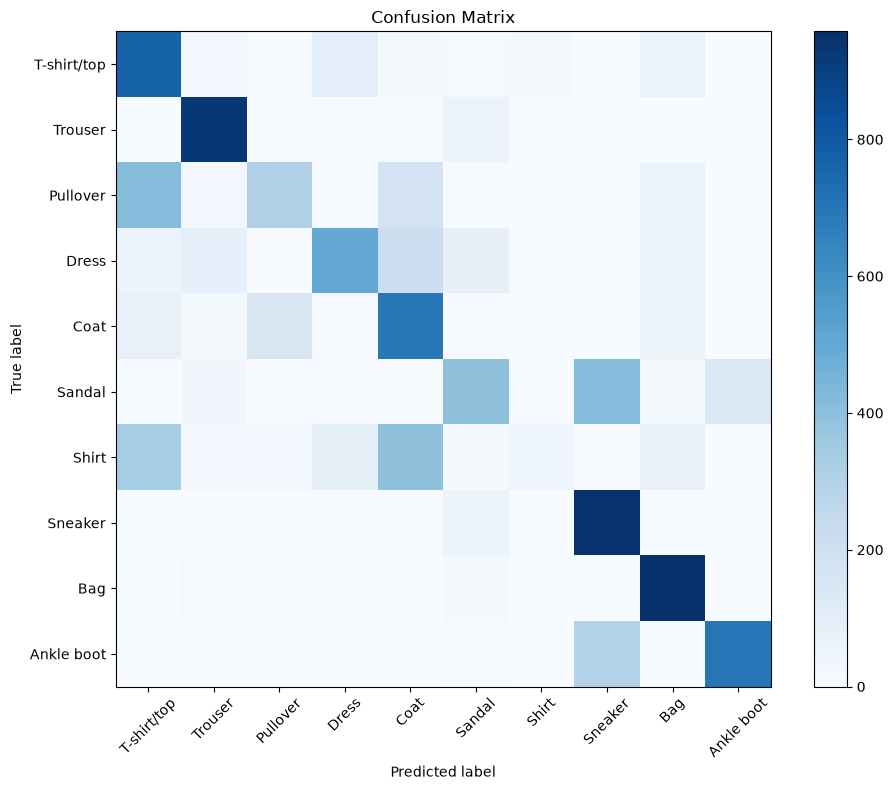

In [8]:
from sklearn.metrics import accuracy_score, confusion_matrix

y_true, y_pred = [], []

# Get the text embeddings of the features
text_feats = get_text_embeddings(CLASS_NAMES)

for pixel_values, labels in test_loader:
    # Get image embeddings
    image_feats = get_image_embeddings(pixel_values)

    # Calculate cosine similarity
    similarity = get_cosine_similarity(
        image_feats,
        text_feats
    )

    # Get predictions
    predictions = get_predictions(similarity)

    # Store actual labels (true labels) and those predicted by the model
    y_true.extend(labels.numpy())
    y_pred.extend(predictions)

# Report the accuracy of the predictions
accuracy = accuracy_score(y_true, y_pred)
print(f'Accuracy: ', accuracy)

# Report the confusion matrix
def plot_confusion_matrix(y_true, y_pred, class_names):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(10, 8))
    plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
    plt.title('Confusion Matrix')
    plt.colorbar()
    tick_marks = np.arange(len(class_names))
    plt.xticks(tick_marks, class_names, rotation=45)
    plt.yticks(tick_marks, class_names)
    plt.ylabel('True label')
    plt.xlabel('Predicted label')
    plt.tight_layout()
    plt.show()

plot_confusion_matrix(y_true, y_pred, CLASS_NAMES)

Reflection: Consider the results. How does the performance of this zero-shot baseline compare to the CNN you trained in Assignment 1? What are the strengths and weaknesses of this approach?

## Improving Zero-Shot Classification with Prompt Engineering

In the previous section, we directly used the class names as text prompts for zero-shot classification. However, we can often improve performance by crafting more descriptive prompts that better capture the visual characteristics of each class. For example, instead of just "T-shirt/top", we could use "a photo of a T-shirt" or "a photo of a top". This additional context can help the model make more accurate predictions.

In this section, we will experiment with more detailed prompts for each class to see if we can improve the zero-shot classification performance. You should:

- [ x ] Create a list of improved prompts for each class. For example, instead of just "T-shirt/top", you could use "a photo of a T-shirt" or "a photo of a top".
- [ x ] Use the `get_text_embeddings` function to create text embeddings for the improved prompts.
- [ x ] Run the zero-shot classification baseline again using the improved prompts and report the accuracy and confusion matrix.

Note: Take advantage of the confusion matrix above. If two classes are often confused, consider how you might improve the prompts to help the model distinguish them better.

The aim for this section is for you to improve the performance of the model. However, if you find that the performance does not improve significantly, you can still reflect on the process and consider how you might further refine the prompts with more effort.

New Accuracy: 0.6004
New Accuracy: 60.04%


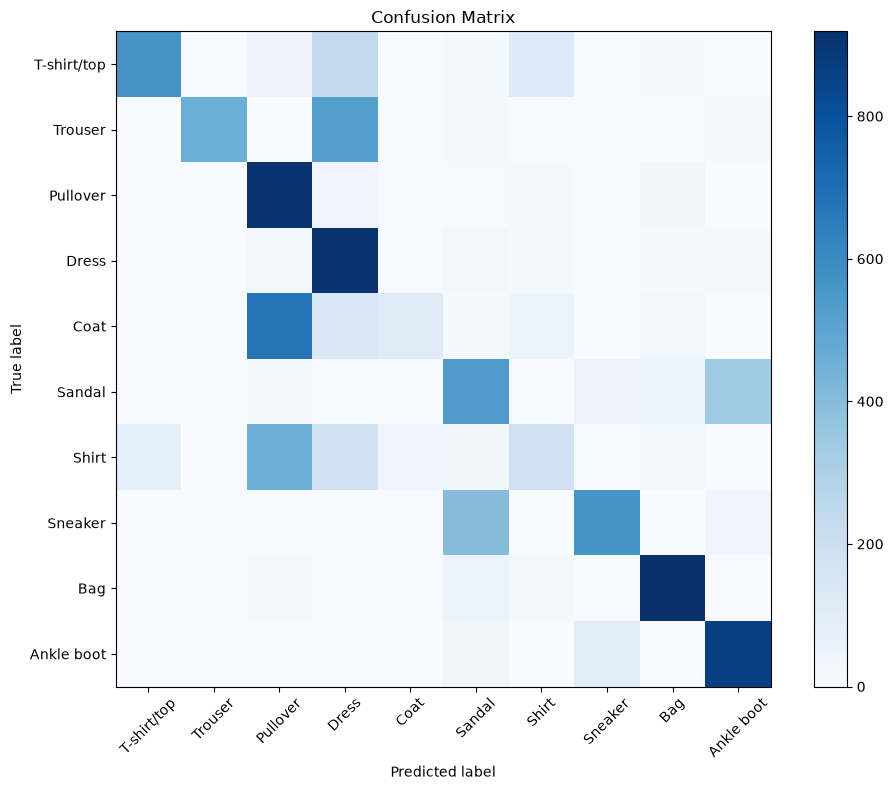

Baseline Accuracy: 62.40%
New Accuracy: 60.04%
Change in accuracy compared to baseline: -2.36 percentage points


In [9]:
new_prompts = [
    "short sleeve t-shirt",
    "trousers or pants",
    "pullover sweater with long-sleeves",
    "casual dress, should be long enough to cover legs and torso. person will not be in image",
    "coat with long-sleeves for cold weather",
    "open-toad sandal", # some of the sandal classifications are things I wouldn't have labeled as sandals
    "business casual shirt with sleeves",
    "sneaker excluding boots",
    "handbag",
    "close-toed tall ankle boot"
]

# New text embeddings
new_text_embeddings = get_text_embeddings(new_prompts)

new_y_true = []
new_y_pred = []

for pixel_values, labels in test_loader:

    image_embeddings = get_image_embeddings(pixel_values)

    similarity = get_cosine_similarity(
        image_embeddings,
        new_text_embeddings
    )

    predictions = get_predictions(similarity)

    new_y_true.extend(labels.numpy())
    new_y_pred.extend(predictions)

# Calculate accuracy
new_accuracy = accuracy_score(
    new_y_true,
    new_y_pred
)

print(f"New Accuracy: {new_accuracy:.4f}")
print(f"New Accuracy: {new_accuracy * 100:.2f}%")

# Plot confusion matrix
plot_confusion_matrix(
    new_y_true,
    new_y_pred,
    CLASS_NAMES
)

# Compare results
print(f"Baseline Accuracy: {accuracy * 100:.2f}%")
print(f"New Accuracy: {new_accuracy * 100:.2f}%")

print(
    f"Change in accuracy compared to baseline: "
    f"{(new_accuracy - accuracy) * 100:.2f} percentage points"
)

Reflection: How did your detailed prompts affect the zero-shot classification performance? Did you see a significant improvement compared to the baseline? What insights did you gain about the model's understanding of the classes? Do you think that with more effort you could further improve the performance? If so, how?

## Visualizing Image Embeddings with UMAP

To better understand how the model perceives the different classes, we can visualize the image embeddings using UMAP (Uniform Manifold Approximation and Projection). UMAP is a dimensionality reduction technique that helps us see how similar or dissimilar the embeddings are in a lower-dimensional space.

By visualizing the embeddings, we can gain insights into how well the model can distinguish certain images, even without considering the text prompts. This can help us identify clusters of similar images and see if there are any overlaps between classes.

You should:

- [ x ] Use the `get_image_embeddings` function to get the image embeddings for the entire test set.
- [ x ] Use UMAP to reduce the dimensionality of the image embeddings to 2D.
- [ x ] Plot the 2D embeddings, coloring each point by its true class label.

You may need to install the `umap-learn` library if you haven't already. You can do this by running `pip install umap-learn`.

In [10]:
# Uncomment the following line to install UMAP if you haven't already
# !pip install umap-learn

2026-11-16 13:29:25.170895: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-11-16 13:29:25.211947: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-11-16 13:29:26.467571: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-11-16 13:29:26.468284: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:31]

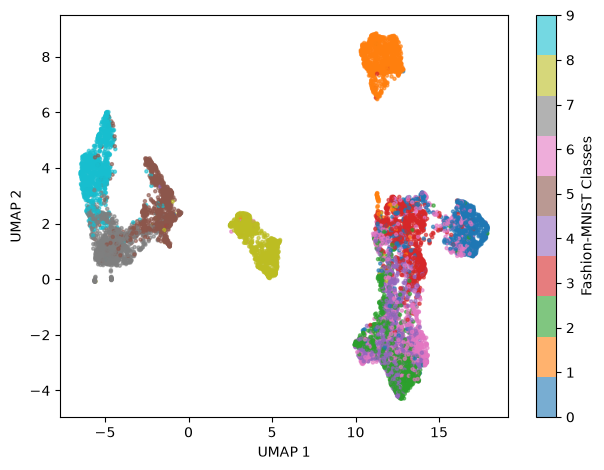

In [11]:
from umap import UMAP

# ------------------------------------------------------------
# 1. Collect image embeddings
# ------------------------------------------------------------
all_img_emb = []
all_labels  = []

for pixel_values, labels in test_loader:
    
    image_embeddings = get_image_embeddings(pixel_values)

    all_img_emb.append(image_embeddings.cpu().numpy())
    all_labels.extend(labels.numpy())

# all image embeddings
all_img_emb = np.concatenate(all_img_emb, axis=0)
all_labels = np.array(all_labels)

# ------------------------------------------------------------
# 2. Fit UMAP
# ------------------------------------------------------------

umap_model = UMAP(
    n_components=2,
    n_neighbors=15,
    min_dist=0.1,
    metric="cosine",
    random_state=42
)

embeddings_2d = umap_model.fit_transform(all_img_emb)

# ------------------------------------------------------------
# 3. Plot coloured by ground-truth label
# ------------------------------------------------------------

plt.figure()

scatter = plt.scatter(
    embeddings_2d[:, 0],
    embeddings_2d[:, 1],
    c=all_labels,
    cmap="tab10",
    s=5,
    alpha=0.6
)

plt.colorbar(
    scatter,
    ticks=range(10),
    label="Fashion-MNIST Classes"
)

plt.xlabel("UMAP 1")
plt.ylabel("UMAP 2")

plt.tight_layout()
plt.show()

The UMAP embeddings allow us to see how separable or non-separable different classes are with our specific model. If two specific images are very similar, then they will be placed near each other on this graph. 

Reflection: Do you notice any challenges in distinguishing images based on this figure? Are there any types of clothing in the dataset which the model has no trouble distinguishing from the others?

## Mini-Experiment

In this section, you will conduct a mini-experiment of your choice to further explore the capabilities of zero-shot classification with transformers. This can be anything you'd like, but here are some ideas to get you started.

### A. Alternative Model

So far we have been utilizing OpenAI's CLIP model for zero-shot classification. However, there are many other vision–language models available in the `transformers` library that you can experiment with. For example, there are larger CLIP models such as [clip-vit-large-patch14](https://huggingface.co/openai/clip-vit-large-patch14), and open-source versions such as [laion/CLIP-ViT-B-32-laion2B-s34B-b79K](https://huggingface.co/laion/CLIP-ViT-B-32-laion2B-s34B-b79K). You can also search huggingface [here](https://huggingface.co/models?sort=trending&search=clip) to find other models that might be suitable for zero-shot classification.

You can try using a different model to see if it improves the zero-shot classification performance. You should:
- [ ] Load a different model and processor from the `transformers` library.
- [ ] Run the zero-shot classification baseline with the new model and report the accuracy and confusion matrix.
- [ ] Reflect on the performance of the new model compared to the original CLIP model
  - How does the new model perform compared to the original CLIP model?
  - Do you notice any differences in the types of errors made by the new model?

### B. Multiple-Description Classification

Another interesting experiment is to explore multiple-description classification. *This involves providing multiple text prompts for each class, allowing the model to choose the most relevant one. For example, instead of just "T-shirt/top", you could provide "a photo of a T-shirt", "a photo of a top", and "a photo of a shirt". This can help the model better understand the class and increases the likelihood of a correct prediction. You should:

- [ ] Create a list of multiple prompts for each class.
- [ ] Use the `get_text_embeddings` function to create text embeddings for the multiple prompts.
- [ ] Run the zero-shot classification baseline again using the multiple prompts and report the accuracy and confusion matrix.
- [ ] Consider the model to be correct if it guesses *any* of the prompts belonging to the correct class.

### C. Top-K Classification

In some classification tasks, it can be useful to consider if the right answer is among the top K (e.g. top 3) predictions. This can be particularly useful in cases where the model is uncertain or when there are multiple similar classes. You should:

- [ x ] Modify the `get_predictions` function to return the top K predictions for each image.
- [ x ] Modify the accuracy calculation to consider the model correct if the true class is among the top K predictions.
- [ x ] Report the accuracy and confusion matrix for the top K predictions. Report at least two different values of K (e.g. K=2 and K=4).

### D. Other Ideas

You are welcome to come up with your own mini-experiment! Explain your idea in the report and implement it. Did it work as you expected? What did you learn from it?

TOP-K CLASSIFICATION RESULTS
----------------------------
Top-1 Accuracy: 62.40%
Top-2 Accuracy: 81.46%
Top-4 Accuracy: 92.45%


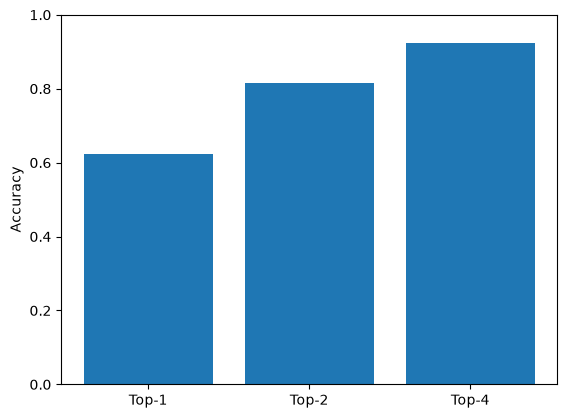

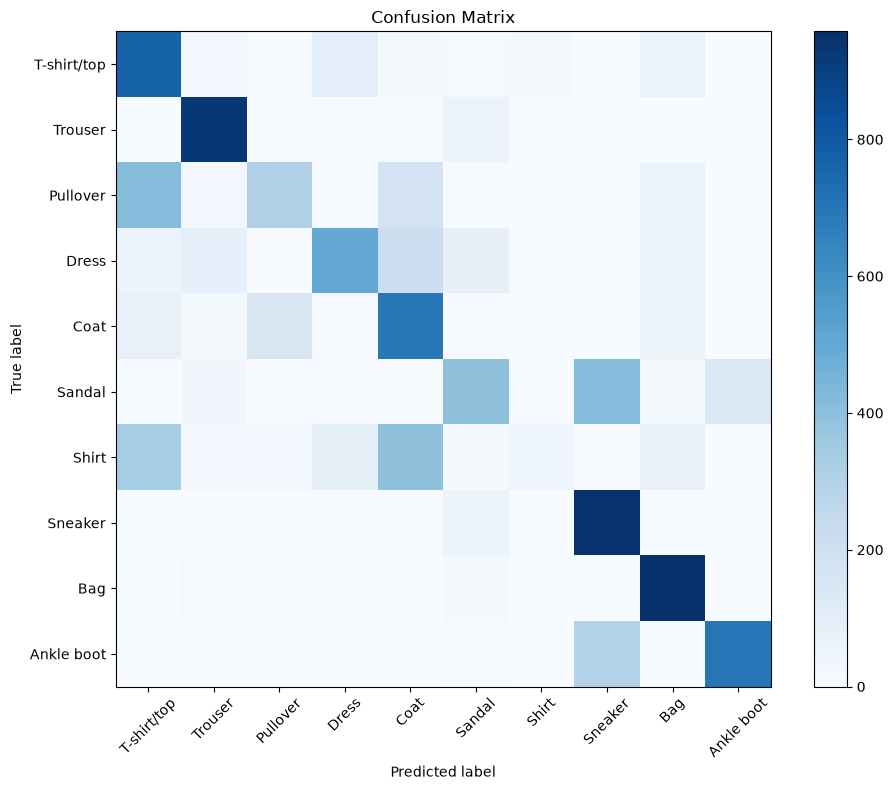

In [12]:
####### TOP-K CLASSIFICATION ########

# Text embeddings
text_embeddings = get_text_embeddings(CLASS_NAMES)

all_true = []
all_top1 = []
all_top2 = []
all_top4 = []

for pixel_values, labels in test_loader:

    # Image embeddings
    image_embeddings = get_image_embeddings(pixel_values)

    # Cosine similarity
    similarity = get_cosine_similarity(
        image_embeddings,
        text_embeddings
    )

    # Get top 4 predictions
    top4_predictions = np.argsort(
        similarity,
        axis=1
    )[:, -4:][:, ::-1]

    # Save results
    all_true.extend(labels.numpy())

    all_top1.extend(top4_predictions[:, 0])
    all_top2.extend(top4_predictions[:, :2])
    all_top4.extend(top4_predictions[:, :4])

all_true = np.array(all_true)
all_top1 = np.array(all_top1)
all_top2 = np.array(all_top2)
all_top4 = np.array(all_top4)

# Top-1 accuracy
top1_accuracy = np.mean(all_true == all_top1)

# Top-2 accuracy
top2_accuracy = np.mean([
    all_true[i] in all_top2[i]
    for i in range(len(all_true))
])

# Top-4 accuracy
top4_accuracy = np.mean([
    all_true[i] in all_top4[i]
    for i in range(len(all_true))
])

# Display results
print("TOP-K CLASSIFICATION RESULTS")
print("----------------------------")
print(f"Top-1 Accuracy: {top1_accuracy * 100:.2f}%")
print(f"Top-2 Accuracy: {top2_accuracy * 100:.2f}%")
print(f"Top-4 Accuracy: {top4_accuracy * 100:.2f}%")

# Plot accuracy comparison
plt.figure()

k_values = ["Top-1", "Top-2", "Top-4"]
accuracies = [
    top1_accuracy,
    top2_accuracy,
    top4_accuracy,
]

plt.bar(
    k_values,
    accuracies,
)

plt.ylabel("Accuracy")
plt.ylim(0, 1)

plt.show()

# Confusion matrix for top-1
plot_confusion_matrix(
    all_true,
    all_top1,
    CLASS_NAMES
)

### Short Report

In this section, you will write a short report summarizing your findings from the mini-experiment. The report should include the following sections:

- **Introduction**: Briefly describe the mini-experiment you conducted and its objectives.
- **Methodology**: Explain the steps you took to conduct the experiment, including any modifications you made to the code or model.
- **Results**: Present the results of your experiment.
- **Discussion**: Reflect on the performance of the model and the implications of your findings. Consider the strengths and weaknesses of zero-shot transformers versus a trained CNN.

#### Introduction
The goal of my experiment is to determine if using a k rank cutoff (e.g., top 1, 2, or 4) of cosine similarity can predict the true label. In practice, this would be useful if the objective is to determine what labels are the most likely rather than confidence that the top label is correct. This can be useful if we don't believe the labels are mutually exclusive (e.g., when a pullover could also be considered a shirt) or we know a priori that our input data may miss features of the item we're trying to predict like low resolution making it difficult to identify clothing texture or grayscaling removing color.

#### Methodology
My experiment has three main stages: 1) obtaining embeddings, 2) calculating cosine similarity, and 3) sorting/selecting the top k predictions based on cosine similarity.

1) Obtaining embeddings: I extract the text and image embeddings using the `get_text_embeddings()` and `get_image_embeddings()` functions, respectively. These functions collect the normalized text and image embeddings for each image based on the pre-trained vision-language model CLIP. CLIP was pre-trained on hundreds of millions of image-text pairs scraped from the web.

2) Calculating cosine similarity: I calculate cosine similarity between images and text prompts using the `get_cosine_similarity()` function. The `get_cosine_similarity()` function just calculates the dot product of the image and text features.

3) Selection of top k predictions: Cosine similarity between images and text prompts are sorted from largest to smallest (most to least similar). The sorted array is then subset to only obtain either the top 1, 2 or 4 labels (i.e., the labels most similar to the images based on the text prompts).

#### Results
The true label is the best predicted label 62.4% of the time. The true label is in the top 2 and top 4 predictions 81.46% and 92.45% of the time, respectively. Some images tend to consistently be mislabeled. For instance, sandals are often mislabeled as sneakers and shirts are often mislabeled as coats. Conceptually, this makes sense because those labels don't seem as semantically different as "shirt" and "sneaker".

#### Discussion
The performance of the mini-experiment model (top-k ranking) and the baseline zero-shot classification (top-1 ranking) model are identical for the best predicted label because they are the same selection. Obviously, including more likely predictions increases the accuracy of the model with including the top-4 predictions increasing accuracy to 92.45%. The increase is because the probability that the true label is in a larger array increases with the size of the array (e.g., we are more likely to be right when predicting four times than one time). Whether increasing the selection window for k-ranks is acceptable will depend on the end goals of the user. For instance, a user may want to pre-sort items to different areas of a store as long as the item is accurately predicted as footwear (sandal, sneaker, or ankle-boot) or a top (shirt, pullover, coat) is sufficient for presorting to the correct department before employees stock the floor. Sorting to high accuracy may waste resources at the first sorting step if employees on the ground do not know the layout they need to stock the department beyond those broad categoies or information about current inventory/space needed for more specific layouts is delayed (i.e., high-accuracy sorting is a waste of resources if the user is unable to use it effectively over a more general pre-sorting).

The main strength of a pre-trained zero-shot transformer versus a trained CNN is that using the final embeddings of the pre-trained network like CLIP means you can leverage the results of a dataset that has used a lot more data and a lot more computational power than most users would feasibly have access to. However, that may lead to inflexibility in some cases. For example, if a pre-trained image classifier can effectively distinguish plant species at scale over broad phylogenetic distances, this might come at a cost to species distinctions of very closely-related species with very similar morphologies. In this case, a custom, trained CNN may be more effective even with less training data because the input data is curated for that specific task rather than a generalizable task. In the case of the Fashion-MNIST model, the labels and predictions are good for distinguishing between shirts and sandals but not so much between sandals and high heels. An end user may need a more specific model that splits sandals and high heels into separate categories.

🚨 **Please review our [Assignment Submission Guide](https://github.com/UofT-DSI/onboarding/blob/main/onboarding_documents/submissions.md)** 🚨 for detailed instructions on how to format, branch, and submit your work. Following these guidelines is crucial for your submissions to be evaluated correctly.
### Submission Parameters:
* Submission Due Date: `23:59 PM - 02/11/2025`
* The branch name for your repo should be: `assignment-2`
* What to submit for this assignment:
    * This Jupyter Notebook (assignment_2.ipynb)
    * The Lab 4 notebook (labs/lab_4.ipynb)
    * The Lab 5 notebook (labs/lab_5.ipynb)
    * The Lab 6 notebook (labs/lab_6.ipynb)
* What the pull request link should look like for this assignment: `https://github.com/<your_github_username>/deep_learning/pull/<pr_id>`
* Open a private window in your browser. Copy and paste the link to your pull request into the address bar. Make sure you can see your pull request properly. This helps the technical facilitator and learning support staff review your submission easily.
Checklist:
- [ x ] Created a branch with the correct naming convention.
- [ x ] Ensured that the repository is public.
- [ x ] Reviewed the PR description guidelines and adhered to them.
- [ x ] Verify that the link is accessible in a private browser window.
If you encounter any difficulties or have questions, please don't hesitate to reach out to our team via our Slack at `#cohort-7-help-ml`. Our Technical Facilitators and Learning Support staff are here to help you navigate any challenges.